# Project RAZE Poker: Exploratory Data Analysis

### Checklist:

#### 1. Data quality and sample choice
#### 2. Population and threshold
#### 3. Time structure
#### 4. Player statistics
#### 5. Big wins and losses
#### 6. Showdowns and all-ins
#### 7. Win rates

### Imports

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

folder_names = [
    "ABS-2009-07-01_2009-07-23_50NLH_OBFU","ABS-2009-07-01_2009-07-23_100NLH_OBFU",
    "ABS-2009-07-01_2009-07-23_200NLH_OBFU","ABS-2009-07-01_2009-07-23_400NLH_OBFU",
    "ABS-2009-07-01_2009-07-23_600NLH_OBFU", "ABS-2009-07-01_2009-07-23_1000NLH_OBFU",
    "FTP-2009-07-01_2009-07-23_50NLH_OBFU", "FTP-2009-07-01_2009-07-23_600NLH_OBFU",
    "FTP-2009-07-01_2009-07-23_1000NLH_OBFU",
    "ONG-2009-07-01_2009-07-23_400NLH_OBFU","ONG-2009-07-01_2009-07-23_600NLH_OBFU",
    "ONG-2009-07-01_2009-07-23_1000NLH_OBFU",
    "PS-2009-07-01_2009-07-23_25NLH_OBFU", "PS-2009-07-01_2009-07-23_50NLH_OBFU",
    "PS-2009-07-01_2009-07-23_200NLH_OBFU", "PS-2009-07-01_2009-07-23_400NLH_OBFU",
    "PS-2009-07-01_2009-07-23_600NLH_OBFU","PS-2009-07-01_2009-07-23_1000NLH_OBFU",
    "PTY-2009-07-01_2009-07-23_25NLH_OBFU","PTY-2009-07-01_2009-07-23_400NLH_OBFU",
    "PTY-2009-07-01_2009-07-23_600NLH_OBFU","PTY-2009-07-01_2009-07-23_1000NLH_OBFU",
] #removed ipoker venue since it has missing stacks data

### 1. Data quality and sample choice

In [14]:
sample_df = pd.read_parquet(f"cleaned_data/PS-2009-07-01_2009-07-23_50NLH_OBFU/parsed_parquet_parts")
sample_df.head()

,file,variant,handId,tableId,venue,actions,n_seats,player_seats,blinds,antes,players,starting_stacks
0,ps NLH handhq_1-OBFUSCATED.phhs,NT,59937793578,QOgaEqMcJ73pcUMMxoisUg,PokerStars,"[d dh p1 ????, d dh p2 ????, d dh p3 ????, d d...",6.0,"[6, 1, 2, 3, 4, 5]","[0.25, 0.5, 0.0, 0.0, 0.0, 0.0]","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0]","[s83dnhZ6VC53vY0/f6OV/g, RFefXIDyFvNtJLq+CloCz...","[40.9, 42.95, 17.85, 22.6, 187.45, 70.85]"
1,ps NLH handhq_1-OBFUSCATED.phhs,NT,59937795962,iq+aXfWVQRdV0u8SRTYUEg,PokerStars,"[d dh p1 ????, d dh p2 ????, d dh p3 ????, d d...",9.0,"[4, 5, 6, 8, 9, 1, 3]","[0.25, 0.5, 0.0, 0.0, 0.0, 0.0, 0.0]","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]","[+Z4e6ELfE9slw801LJ3vAw, MZo49KUcOZcn7g/WRL0Vq...","[16.5, 43.65, 30.9, 31.8, 9.75, 13.35, 123.0]"
2,ps NLH handhq_1-OBFUSCATED.phhs,NT,59937796506,E7bWJ45aoFXRpyRv2gw+Ig,PokerStars,"[d dh p1 ????, d dh p2 ????, p2 f]",2.0,"[1, 2]","[0.25, 0.5]","[0.0, 0.0]","[FRkiRasEGlHUeLrEl+k/nA, 3Wro85I7472vJ4Wkpneo9A]","[50.2, 75.75]"
3,ps NLH handhq_1-OBFUSCATED.phhs,NT,59937797158,+dXkOAQyS8j9PQZusUTMpg,PokerStars,"[d dh p1 ????, d dh p2 ????, p2 cbr 1.50, p1 f]",2.0,"[2, 1]","[0.25, 0.5]","[0.0, 0.0]","[5IBeOgaApY1Bvzv2P8X4EA, XFa6sBGjP2gxoIvxR3fZIg]","[24.5, 79.45]"
4,ps NLH handhq_1-OBFUSCATED.phhs,NT,59937798704,kgbJRsxfv64KrErDRBAkcw,PokerStars,"[d dh p1 ????, d dh p2 ????, d dh p3 ????, d d...",6.0,"[5, 6, 1, 2, 3, 4]","[0.25, 0.5, 0.0, 0.0, 0.0, 0.0]","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0]","[SlTdlH14u+KVVINgxMwt+Q, DDfYzIrYT0t5R/hAJngts...","[74.8, 19.75, 84.3, 98.7, 61.95, 50.0]"


In [15]:
# checking n_seats in each file
for f_name in folder_names:
    current_df = pd.read_parquet(f"cleaned_data/{f_name}/parsed_parquet_parts")
    print(f'{f_name}:')
    print(current_df["n_seats"].value_counts(dropna=False))
    print('''
    ''')

ABS-2009-07-01_2009-07-23_50NLH_OBFU:
n_seats
None    389834
Name: count, dtype: int64

    
ABS-2009-07-01_2009-07-23_100NLH_OBFU:
n_seats
None    323464
Name: count, dtype: int64

    
ABS-2009-07-01_2009-07-23_200NLH_OBFU:
n_seats
None    309176
Name: count, dtype: int64

    
ABS-2009-07-01_2009-07-23_400NLH_OBFU:
n_seats
None    142072
Name: count, dtype: int64

    
ABS-2009-07-01_2009-07-23_600NLH_OBFU:
n_seats
None    39282
Name: count, dtype: int64

    
ABS-2009-07-01_2009-07-23_1000NLH_OBFU:
n_seats
None    66830
Name: count, dtype: int64

    
FTP-2009-07-01_2009-07-23_50NLH_OBFU:
n_seats
NaN    289678
6.0    230577
Name: count, dtype: int64

    
FTP-2009-07-01_2009-07-23_600NLH_OBFU:
n_seats
6.0    204805
NaN    194248
Name: count, dtype: int64

    
FTP-2009-07-01_2009-07-23_1000NLH_OBFU:
n_seats
6.0    202971
NaN    177224
Name: count, dtype: int64

    
ONG-2009-07-01_2009-07-23_400NLH_OBFU:
n_seats
None    984256
Name: count, dtype: int64

    
ONG-2009-07-01_2009-07-

In [16]:
# making a dataframe for the above
number_seats_df = None
rows = []

for folder_name in folder_names:

    df = pd.read_parquet(f"cleaned_data/{folder_name}/parsed_parquet_parts")


    name = folder_name.split('-')[0] + '-' + folder_name.split('-')[-1][:-5]
    seat_number_na = len(df[df["n_seats"].isna()])
    seat_number_6 = len(df[df["n_seats"] == 6.0])
    seat_number_2 = len(df[df["n_seats"] == 2.0])
    seat_number_9 = len(df[df["n_seats"] == 9.0])

    rows.append({"Collection": name, "6 Seat Tables":  seat_number_6, "9 Seat Tables":  seat_number_9,
                 "2 Seat Tables":  seat_number_2, "Missing Seats Number":  seat_number_na})
    
number_seats_df = pd.DataFrame(rows)
number_seats_df

,Collection,6 Seat Tables,9 Seat Tables,2 Seat Tables,Missing Seats Number
0,ABS-23_50NLH,0,0,0,389834
1,ABS-23_100NLH,0,0,0,323464
2,ABS-23_200NLH,0,0,0,309176
3,ABS-23_400NLH,0,0,0,142072
4,ABS-23_600NLH,0,0,0,39282
5,ABS-23_1000NLH,0,0,0,66830
6,FTP-23_50NLH,230577,0,0,289678
7,FTP-23_600NLH,204805,0,0,194248
8,FTP-23_1000NLH,202971,0,0,177224
9,ONG-23_400NLH,0,0,0,984256


#### Number of players with over 1000 hands at 6 seat tables

In [18]:
players_over_1000_df = None
rows = []


for folder_name in folder_names:

    df = pd.read_parquet(f"cleaned_data/{folder_name}/parsed_parquet_parts")
    df = df[df["n_seats"]==6.0]
    
    players_df = df["players"].explode().value_counts()
    players_df = players_df.reset_index(name='Hands Played')

    players_num = (players_df['Hands Played'] >= 1000).sum()
    name = folder_name.split('-')[0] + '-' + folder_name.split('_')[-2]
    rows.append({"Collection": name, "Players With Over 1000 Hands": players_num})

players_over_1000_df = pd.DataFrame(rows)
players_over_1000_df

,Collection,Players With Over 1000 Hands
0,ABS-50NLH,0
1,ABS-100NLH,0
2,ABS-200NLH,0
3,ABS-400NLH,0
4,ABS-600NLH,0
5,ABS-1000NLH,0
6,FTP-50NLH,191
7,FTP-600NLH,222
8,FTP-1000NLH,224
9,ONG-400NLH,0


In [19]:
players_over_500_df = None
rows = []
all_player_dfs = {}

for folder_name in folder_names:

    df = pd.read_parquet(f"cleaned_data/{folder_name}/parsed_parquet_parts")
    df = df[df["n_seats"]==6.0]
    
    players_df = df["players"].explode().value_counts()
    players_df = players_df.reset_index(name='Hands Played')
    all_player_dfs[folder_name] = players_df

    players_num = (players_df['Hands Played'] >= 500).sum()
    name = folder_name.split('-')[0] + '-' + folder_name.split('_')[-2]
    rows.append({"Collection": name, "Players With Over 500 Hands": players_num})

players_over_500_df = pd.DataFrame(rows)
players_over_500_df

,Collection,Players With Over 500 Hands
0,ABS-50NLH,0
1,ABS-100NLH,0
2,ABS-200NLH,0
3,ABS-400NLH,0
4,ABS-600NLH,0
5,ABS-1000NLH,0
6,FTP-50NLH,530
7,FTP-600NLH,418
8,FTP-1000NLH,390
9,ONG-400NLH,0


In [20]:
all_player_dfs["PS-2009-07-01_2009-07-23_25NLH_OBFU"]

,players,Hands Played
0,kG34n23qFQA3nzdOJTQ1dA,34424
1,cPO/1/dTcZpLkQFm3jH3Rg,31169
2,8ClCHtFXGNplITm+63KB+Q,29328
3,Q1uciOZPBR/WkAlqa6cL4A,23639
4,HtELMnIpQzpcPXm89PVHjA,22161
...,...,...
36755,edwRm+wpt6jWTThG4Y4WoA,1
36756,q2fqFUJQZ2sFg7D4iIF61Q,1
36757,N2y/wLchafoaByPQdkfXUw,1
36758,AUJxk36kY5ZfaUhZZJ3VMw,1


In [21]:
#### plotting distributions of players and number of hands

In [22]:
counts = (pd.concat(all_player_dfs, names=["Collection", None])    # pandas: dict keys become a label
            .reset_index(level="Collection"))                        # turn that label into a column

In [23]:
# filtering for these 2 candidate folders I picked
plot_df = counts[counts["Collection"].isin(["PS-2009-07-01_2009-07-23_25NLH_OBFU", "PS-2009-07-01_2009-07-23_200NLH_OBFU"])]
plot_df

,Collection,players,Hands Played
0,PS-2009-07-01_2009-07-23_25NLH_OBFU,kG34n23qFQA3nzdOJTQ1dA,34424
1,PS-2009-07-01_2009-07-23_25NLH_OBFU,cPO/1/dTcZpLkQFm3jH3Rg,31169
2,PS-2009-07-01_2009-07-23_25NLH_OBFU,8ClCHtFXGNplITm+63KB+Q,29328
3,PS-2009-07-01_2009-07-23_25NLH_OBFU,Q1uciOZPBR/WkAlqa6cL4A,23639
4,PS-2009-07-01_2009-07-23_25NLH_OBFU,HtELMnIpQzpcPXm89PVHjA,22161
...,...,...,...
13598,PS-2009-07-01_2009-07-23_200NLH_OBFU,ak8Nb/nHLg5VnRJnW6qwSg,1
13599,PS-2009-07-01_2009-07-23_200NLH_OBFU,lBrK7LZBb3XG7jVNlu76Mg,1
13600,PS-2009-07-01_2009-07-23_200NLH_OBFU,vfMvjqXQ/p8iBolZCabkJw,1
13601,PS-2009-07-01_2009-07-23_200NLH_OBFU,DBauFdk2YanrI3KQpYHMwg,1


<Axes: xlabel='Hands Played', ylabel='Count'>

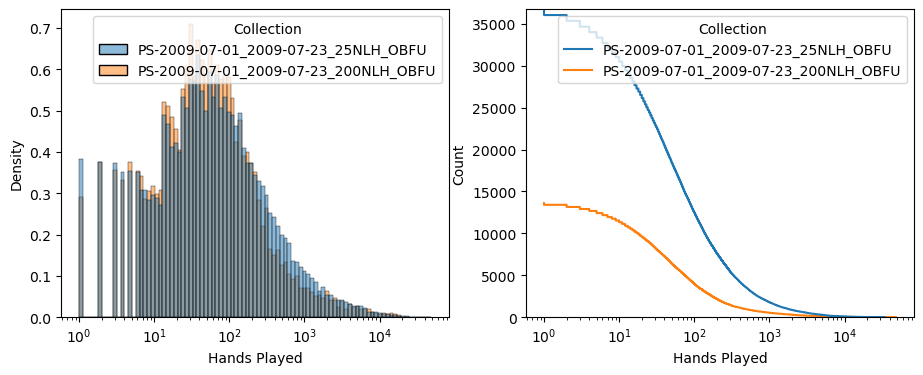

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.histplot(data=plot_df, x="Hands Played", hue="Collection",
             log_scale=True, stat="density", common_norm=False, ax=axes[0])

sns.ecdfplot(data=plot_df, x="Hands Played", hue="Collection",
             complementary=True, stat="count", log_scale=True, ax=axes[1])

In [25]:
plot_df.groupby("Collection")["Hands Played"].describe(percentiles=[0.5, 0.9, 0.99])

,count,mean,std,min,50%,90%,99%,max
Collection,,,,,,,,
PS-2009-07-01_2009-07-23_200NLH_OBFU,13603.0,234.736529,1135.593670,1.0,45.0,319.0,4130.72,48710.0
PS-2009-07-01_2009-07-23_25NLH_OBFU,36760.0,257.253455,957.893609,1.0,51.0,470.0,4076.00,34424.0


### Key Takeaways:
##### - The distributions have a similar shape, differing mainly in size, though 25NL has relatively more moderately active players (90th percentile 470 against 319 hands).
##### - Although requiring players to have a higher minimum number of hands played significantly reduces the number of players, we decided the tradeoff is worth it as their betting statistics would be more accurate with a larger hand count.


In [27]:
#next to do is check for this folder if we have dates and times, and do we really need those if so why?

### Re extracting data from phh files to include date and time variables

In [46]:
! pip install pokerkit

In [50]:
# ONLY NEED TO RUN ONCE since files are downloaded
#import pokerkit
#from EDA_phh_parsing import parse_folder
#parse_folder(raw_folder_name="PS-2009-07-01_2009-07-23_200NLH_OBFU", venue="PokerStars", folder_name="PS-200NLH_with_timestamp")

C:\Users\eesag\anaconda3\Lib\site-packages\pokerkit\notation.py:434: UserWarning: The field 'time_zone_abbreviation' is an unexpected field and should probably be prefixed with an underscore character '_'.
  warn(


File processed: ps NLH handhq_1-OBFUSCATED.phhs
File processed: ps NLH handhq_10-OBFUSCATED.phhs
File processed: ps NLH handhq_100-OBFUSCATED.phhs
File processed: ps NLH handhq_1000-OBFUSCATED.phhs
File processed: ps NLH handhq_1001-OBFUSCATED.phhs
File processed: ps NLH handhq_1002-OBFUSCATED.phhs
File processed: ps NLH handhq_1003-OBFUSCATED.phhs
File processed: ps NLH handhq_1004-OBFUSCATED.phhs
File processed: ps NLH handhq_1005-OBFUSCATED.phhs
File processed: ps NLH handhq_1006-OBFUSCATED.phhs
File processed: ps NLH handhq_1007-OBFUSCATED.phhs
File processed: ps NLH handhq_1008-OBFUSCATED.phhs
File processed: ps NLH handhq_1009-OBFUSCATED.phhs
File processed: ps NLH handhq_101-OBFUSCATED.phhs
File processed: ps NLH handhq_1010-OBFUSCATED.phhs
File processed: ps NLH handhq_1011-OBFUSCATED.phhs
File processed: ps NLH handhq_1012-OBFUSCATED.phhs
File processed: ps NLH handhq_1013-OBFUSCATED.phhs
File processed: ps NLH handhq_1014-OBFUSCATED.phhs
File processed: ps NLH handhq_1015-OBF

In [ ]:
info()

In [54]:
PS_200NLH_df = pd.read_parquet("cleaned_data/PS-200NLH_with_timestamp/parsed_parquet_parts")
PS_200NLH_df

,file,time_stamp,handId,tableId,venue,actions,n_seats,player_seats,blinds,antes,players,starting_stacks
0,ps NLH handhq_1-OBFUSCATED.phhs,2009-07-01 00:00:00,59937793530,uJ9juaXXg9yIcSU8amxaXQ,PokerStars,"[d dh p1 ????, d dh p2 ????, d dh p3 ????, d d...",6.0,"[3, 5, 6, 1, 2]","[1.0, 2.0, 0.0, 0.0, 0.0]","[0.0, 0.0, 0.0, 0.0, 0.0]","[zaogaltCDFVsIASEnrXs2w, F/075N6nU34Fn0zr6qD3a...","[247.15, 237.05, 47.9, 208.75, 269.45]"
1,ps NLH handhq_1-OBFUSCATED.phhs,2009-07-01 00:00:00,59937793454,ztv6V3FN2bQ9nmJPPdx6nQ,PokerStars,"[d dh p1 ????, d dh p2 ????, d dh p3 ????, d d...",6.0,"[6, 1, 2, 3, 4, 5]","[1.0, 2.0, 0.0, 0.0, 0.0, 0.0]","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0]","[yZgdnRylE65JbScQ7qCWgw, ek1hig03QiyONDHXvgqte...","[38.0, 199.75, 294.7, 144.45, 318.7, 200.0]"
2,ps NLH handhq_1-OBFUSCATED.phhs,2009-07-01 00:00:03,59937796680,on4i1U1lCRmxsduFD3xiSg,PokerStars,"[d dh p1 ????, d dh p2 ????, d dh p3 ????, d d...",9.0,"[1, 2, 3, 4, 5, 6, 7, 8, 9]","[1.0, 2.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]","[BRHGptvmY2GKq4uuj7duDw, yZYrOeNDxQxkzpbgKX1bn...","[278.6, 70.0, 61.2, 207.3, 200.0, 399.5, 249.2..."
3,ps NLH handhq_1-OBFUSCATED.phhs,2009-07-01 00:00:04,59937797220,RF+CoNlqGlniDSszIP2SGw,PokerStars,"[d dh p1 ????, d dh p2 ????, p2 f]",2.0,"[1, 2]","[1.0, 2.0]","[0.0, 0.0]","[e0oDWyrmgLpR6bROEqw1nQ, jKzajniHFCiIQAQeNkmTGg]","[252.5, 367.5]"
4,ps NLH handhq_1-OBFUSCATED.phhs,2009-07-01 00:00:08,59937800352,HewZCzVOYGmuLDKthTi5Yw,PokerStars,"[d dh p1 ????, d dh p2 ????, d dh p3 ????, d d...",6.0,"[5, 1, 2, 4]","[1.0, 2.0, 0.0, 0.0]","[0.0, 0.0, 0.0, 0.0]","[513FcCI8jHyQy2VWoIQkMg, 353332, X7GlkHF+lkbar...","[375.5, 226.75, 37.0, 41.0]"
...,...,...,...,...,...,...,...,...,...,...,...,...
1197454,ps NLH handhq_999-OBFUSCATED.phhs,2009-07-17 12:22:16,61125431092,/+h7OSUY0DvcTsH/D0ZbQw,PokerStars,"[d dh p1 ????, d dh p2 ????, p2 cbr 4, p1 f]",2.0,"[2, 1]","[1.0, 2.0]","[0.0, 0.0]","[HZNtGru22TgZNvb2RmtFMw, NSP2F9DdmpIqfsKMOxatbQ]","[227.3, 73.2]"
1197455,ps NLH handhq_999-OBFUSCATED.phhs,2009-07-17 12:22:17,61125432000,OATGeOYK6vOuRoVYN5PEHQ,PokerStars,"[d dh p1 ????, d dh p2 ????, d dh p3 ????, d d...",6.0,"[6, 1, 3, 4, 5]","[1.0, 2.0, 0.0, 0.0, 0.0]","[0.0, 0.0, 0.0, 0.0, 0.0]","[fVSI0qOV53oAJIYKN8W06w, VLI7wK0GstC5LmENxxsa0...","[103.75, 225.65, 22.0, 57.5, 200.0]"
1197456,ps NLH handhq_999-OBFUSCATED.phhs,2009-07-17 12:22:18,61125433032,mAaz+nbyeWXafvdSyYxSMQ,PokerStars,"[d dh p1 ????, d dh p2 ????, p2 cc, p1 cbr 10,...",2.0,"[2, 1]","[1.0, 2.0]","[0.0, 0.0]","[TNAC5XiHbhlXQuckeoQzNQ, NYuDJi7YvNQZ8Baebll5gA]","[329.6, 166.4]"
1197457,ps NLH handhq_999-OBFUSCATED.phhs,2009-07-17 12:22:18,61125432768,PsaT7E25XITItPUeb13Zbw,PokerStars,"[d dh p1 ????, d dh p2 ????, p2 cc, p1 cbr 6, ...",2.0,"[2, 1]","[1.0, 2.0]","[0.0, 0.0]","[0yQqkxHEIwe3fsTQIkWZYQ, PFLW8q8lCZIyyY5DNVG8pw]","[401.9, 818.5]"


In [60]:
PS_200NLH_df = PS_200NLH_df[PS_200NLH_df["n_seats"] == 6.0]
# filtering out hands at 6 seat tables only

In [82]:
midnight = PS_200NLH_df["time_stamp"] == PS_200NLH_df["time_stamp"].dt.normalize()
print(midnight.sum(), "hands at exactly midnight")
print(f"{midnight.mean():.4%} of hands")

5 hands at exactly midnight
0.0009% of hands


In [ ]:
# just confirming the data for the times looks correct since its possible midnight was set if it was missing but this small percentage is insignificant

In [94]:
PS_200NLH_df = PS_200NLH_df[["time_stamp", "tableId", "players"]]
PS_200NLH_df

,time_stamp,tableId,players
0,2009-07-01 00:00:00,uJ9juaXXg9yIcSU8amxaXQ,"[zaogaltCDFVsIASEnrXs2w, F/075N6nU34Fn0zr6qD3a..."
1,2009-07-01 00:00:00,ztv6V3FN2bQ9nmJPPdx6nQ,"[yZgdnRylE65JbScQ7qCWgw, ek1hig03QiyONDHXvgqte..."
4,2009-07-01 00:00:08,HewZCzVOYGmuLDKthTi5Yw,"[513FcCI8jHyQy2VWoIQkMg, 353332, X7GlkHF+lkbar..."
7,2009-07-01 00:00:13,CFkQcfWjKccZaZDf71FK+w,"[ygTTt5ehT4aF86q1a8/R+w, B2Ih1sr5VZk+8He7rcrMt..."
8,2009-07-01 00:00:14,fe+AlpfadsfwxhZEvYFbbA,"[SLlqn2PPbQqwfcLfYqUXrw, /PH6Ffnho4Ysm8S3V/oa+..."
...,...,...,...
1197448,2009-07-17 12:22:11,/PpgLeQ+OOMGyyZvSt2d8g,"[vY51IL4w4wWUG3pGIEphVg, yCJP9nHlToEXuSbvipt3P..."
1197451,2009-07-17 12:22:12,U/kpMCmYVhKl5GWwlnCPaw,"[l7WIlwJyHO2eXgwjJ5fPkg, DPZK1z9n4/sVQw7034aDG..."
1197452,2009-07-17 12:22:12,QWpbfjwj978+dNA33wVHIg,"[ntfnAgyLg28vJG5SmpmHVA, yCJP9nHlToEXuSbvipt3P..."
1197455,2009-07-17 12:22:17,OATGeOYK6vOuRoVYN5PEHQ,"[fVSI0qOV53oAJIYKN8W06w, VLI7wK0GstC5LmENxxsa0..."


In [ ]:
### continue making some visualisations to check what gaps separate players plans